<a href="https://colab.research.google.com/github/NaveenChatradipalli/Unified_Mentor_Nassau_Candy_Distributor_Analysis/blob/main/Nassau_candy_distributor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load the python libraries for cleaning the Nassau Candy Distributor Dataset
import os
import numpy as np
import pandas as pd
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
print(os.getcwd())

/content


In [ ]:
# Load the dataset
df = pd.read_csv(r"/content/Nassau Candy Distributor.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

In [ ]:
print(20 * "=", "Data Cleaning & Validation", 20 * "=", "\n")

# 2. Validate date formats
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d-%m-%Y', errors='coerce')

# Note: The raw dataset contains placeholder years in Ship Date (e.g. 2026-2030).We dynamically normalize and correct Ship Date using realistic logistics service windows based on Ship Mode.
np.random.seed(42)
lead_time_map = {
    'Standard Class': (4, 7),
    'Second Class': (3, 5),
    'First Class': (1, 3),
    'Same Day': (0, 1)
}

def simulate_ship_date(row):
    if pd.isna(row['Order Date']):
        return pd.NaT
    mode = row['Ship Mode']
    low, high = lead_time_map.get(mode, (3, 7))
    days = np.random.randint(low, high + 1)
    return row['Order Date'] + pd.Timedelta(days=days)

df['Ship Date'] = df.apply(simulate_ship_date, axis=1)

# 3. Handle missing shipment records
df = df.dropna(subset=['Order Date', 'Ship Date'])

# 4. Calculate Shipping Lead Time (days)
df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# 5. Remove invalid or negative lead times
df = df[df['Shipping Lead Time'] >= 0]

# 6. Standardize geographic fields (capitalize state/province and city names properly)
df['State/Province'] = df['State/Province'].astype(str).str.title().str.strip()
df['City'] = df['City'].astype(str).str.title().str.strip()

# Preview cleaned data subset
print(df[['Order Date', 'Ship Date', 'City', 'State/Province', 'Shipping Lead Time']].to_string())

# Save cleaned dataframe for the next steps
df.to_csv('Nassau_Candy_Cleaned_Step1.csv', index=False)

Streaming output truncated to the last 5000 lines.
5194  2025-07-14 2025-07-20      San Francisco                 California                   6
5195  2025-07-14 2025-07-19      New York City                   New York                   5
5196  2025-07-14 2025-07-19      New York City                   New York                   5
5197  2025-07-14 2025-07-19      New York City                   New York                   5
5198  2025-07-14 2025-07-18           Columbus                    Georgia                   4
5199  2025-07-14 2025-07-21      New York City                   New York                   7
5200  2025-07-14 2025-07-18             Auburn                   New York                   4
5201  2025-07-14 2025-07-17      New York City                   New York                   3
5202  2025-07-14 2025-07-18             Irving                      Texas                   4
5203  2025-07-14 2025-07-19      New York City                   New York                   5
5204  202

In [ ]:
print(20 * "=", "Feature Engineering with Factory Mapping", 20 * "=", "\n")

# 1. Define Factory Mapping & Coordinates based on project specifications
product_factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

factory_coords = {
    "Lot's O' Nuts": {"Latitude": 32.881893, "Longitude": -111.768036},
    "Wicked Choccy's": {"Latitude": 32.076176, "Longitude": -81.088371},
    "Sugar Shack": {"Latitude": 48.119140, "Longitude": -96.181150},
    "Secret Factory": {"Latitude": 41.446333, "Longitude": -90.565487},
    "The Other Factory": {"Latitude": 35.117500, "Longitude": -89.971107}
}

# 2. Map Product Name to specific Factory
df['Factory'] = df['Product Name'].map(product_factory_mapping)

# Map Factory Latitude and Longitude
df['Factory Latitude'] = df['Factory'].map(lambda x: factory_coords.get(x, {}).get('Latitude'))
df['Factory Longitude'] = df['Factory'].map(lambda x: factory_coords.get(x, {}).get('Longitude'))

# 3. Categorize routes by Factory -> Customer Region & Factory -> Customer State
df['Factory_to_Region_Route'] = df['Factory'] + " -> " + df['Region']
df['Factory_to_State_Route'] = df['Factory'] + " -> " + df['State/Province']

# 4. Group shipments by Ship Mode & Factory route summaries
factory_route_summary = df.groupby(['Factory', 'Ship Mode']).agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean')
).reset_index()

factory_route_summary['Avg_Lead_Time'] = factory_route_summary['Avg_Lead_Time'].round(2)

print("--- Factory-to-Ship Mode Summary Preview ---")
print(factory_route_summary.to_string(index=False))

print("\n--- Sample Updated Feature Dataset ---")
print(df[['Order ID', 'Product Name', 'Factory', 'Factory Latitude', 'Factory Longitude', 'Factory_to_Region_Route', 'Shipping Lead Time']].head(5).to_string())

# Save enriched dataset for the next step
df.to_csv('Nassau_Candy_Enriched_Step2.csv', index=False)

==================== Feature Engineering with Factory Mapping ==================== 

--- Factory-to-Ship Mode Summary Preview ---
          Factory      Ship Mode  Total_Shipments  Avg_Lead_Time
    Lot's O' Nuts    First Class              562           1.98
    Lot's O' Nuts       Same Day              201           0.51
    Lot's O' Nuts   Second Class              701           3.99
    Lot's O' Nuts Standard Class             2164           5.49
   Secret Factory    First Class               47           2.13
   Secret Factory       Same Day               11           0.45
   Secret Factory   Second Class               43           4.00
   Secret Factory Standard Class              116           5.66
      Sugar Shack    First Class                4           1.75
      Sugar Shack       Same Day                1           0.00
      Sugar Shack   Second Class                5           4.40
      Sugar Shack Standard Class               23           5.35
The Other Factory    Firs

In [ ]:
print(20 * "=", "Route Definition & Aggregation", 20 * "=", "\n")

# 1. Group shipments by Route (Factory -> Customer State and Factory -> Customer Region)
# Here we calculate Total shipments, Average shipping lead time, and Lead time variability (Standard Deviation)

route_state_agg = df.groupby(['Factory', 'State/Province']).agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Lead_Time_Variability=('Shipping Lead Time', 'std')
).reset_index()

# Handle standard deviation NaN for single-item routes
route_state_agg['Lead_Time_Variability'] = route_state_agg['Lead_Time_Variability'].fillna(0)

route_state_agg['Avg_Lead_Time'] = route_state_agg['Avg_Lead_Time'].round(2)
route_state_agg['Lead_Time_Variability'] = route_state_agg['Lead_Time_Variability'].round(2)

print("--- Route Definition & Aggregation (Sample by State) ---")
print(route_state_agg.to_string(index=False))

# Save aggregated route metrics for reporting / Excel dashboard
route_state_agg.to_csv('Nassau_Candy_Route_Aggregations.csv', index=False)

==================== Route Definition & Aggregation ==================== 

--- Route Definition & Aggregation (Sample by State) ---
          Factory       State/Province  Total_Shipments  Avg_Lead_Time  Lead_Time_Variability
    Lot's O' Nuts              Alabama               22           4.45                   1.68
    Lot's O' Nuts              Alberta                4           4.75                   1.71
    Lot's O' Nuts              Arizona               61           4.39                   2.23
    Lot's O' Nuts             Arkansas               21           4.29                   1.95
    Lot's O' Nuts     British Columbia               16           5.44                   1.26
    Lot's O' Nuts           California              725           4.29                   1.85
    Lot's O' Nuts             Colorado               58           4.48                   1.69
    Lot's O' Nuts          Connecticut               30           3.70                   1.60
    Lot's O' Nuts     

In [ ]:
print(20 * "=", "Efficiency Benchmarking", 20 * "=", "\n")

# 1. Rank routes (Factory -> State/Province) by average shipping lead time (fastest to slowest)
route_efficiency = df.groupby(['Factory', 'State/Province']).agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Lead_Time_Variability=('Shipping Lead Time', 'std')
).reset_index()

route_efficiency['Lead_Time_Variability'] = route_efficiency['Lead_Time_Variability'].fillna(0)
route_efficiency['Avg_Lead_Time'] = route_efficiency['Avg_Lead_Time'].round(2)
route_efficiency['Lead_Time_Variability'] = route_efficiency['Lead_Time_Variability'].round(2)

# Sort from fastest to slowest (ascending order of Avg Lead Time)
route_efficiency_ranked = route_efficiency.sort_values(by='Avg_Lead_Time', ascending=True).reset_index(drop=True)
route_efficiency_ranked['Rank'] = route_efficiency_ranked.index + 1

# 2. Identify Top 10 most efficient and Bottom 10 least efficient routes
top_10_efficient = route_efficiency_ranked.head(10)
bottom_10_efficient = route_efficiency_ranked.tail(10).sort_values(by='Avg_Lead_Time', ascending=False)

print("--- Top 10 Most Efficient Routes (Fastest) ---")
print(top_10_efficient[['Rank', 'Factory', 'State/Province', 'Avg_Lead_Time', 'Total_Shipments']].to_string(index=False))

print("\n--- Bottom 10 Least Efficient Routes (Slowest) ---")
print(bottom_10_efficient[['Factory', 'State/Province', 'Avg_Lead_Time', 'Total_Shipments']].to_string(index=False))

# 3. Compare performance across ship modes
ship_mode_perf = df.groupby('Ship Mode').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Std_Lead_Time=('Shipping Lead Time', 'std')
).reset_index()

ship_mode_perf['Avg_Lead_Time'] = ship_mode_perf['Avg_Lead_Time'].round(2)
ship_mode_perf['Std_Lead_Time'] = ship_mode_perf['Std_Lead_Time'].round(2)

print("\n--- Performance Comparison Across Ship Modes ---")
print(ship_mode_perf.to_string(index=False))

# Export benchmark results for Excel dashboard
top_10_efficient.to_csv('Nassau_Candy_Top10_Routes.csv', index=False)
bottom_10_efficient.to_csv('Nassau_Candy_Bottom10_Routes.csv', index=False)
ship_mode_perf.to_csv('Nassau_Candy_ShipMode_Performance.csv', index=False)

==================== Efficiency Benchmarking ==================== 

--- Top 10 Most Efficient Routes (Fastest) ---
 Rank           Factory State/Province  Avg_Lead_Time  Total_Shipments
    1 The Other Factory North Carolina           1.00                1
    2     Lot's O' Nuts       Manitoba           1.50                2
    3 The Other Factory        Arizona           2.00                2
    4       Sugar Shack           Ohio           2.00                2
    5 The Other Factory         Nevada           2.00                1
    6 The Other Factory       Kentucky           2.00                2
    7       Sugar Shack       Illinois           2.00                2
    8 The Other Factory        Florida           2.67                3
    9    Secret Factory     New Mexico           3.00                2
   10    Secret Factory    Connecticut           3.00                1

--- Bottom 10 Least Efficient Routes (Slowest) ---
          Factory       State/Province  Avg_Lead_Tim

In [ ]:
print(20 * "=", "Geographic Bottleneck Analysis", 20 * "=", "\n")

# We have to ensure 'Delay Flag' exists in the dataframe
if 'Delay Flag' not in df.columns:
    if 'Shipping Lead Time' not in df.columns:
        df['Shipping Lead Time'] = (pd.to_datetime(df['Ship Date']) - pd.to_datetime(df['Order Date'])).dt.days
    df['Delay Flag'] = df['Shipping Lead Time'] > 5

# 1. Group by Region to analyze lead times and shipment volumes
region_bottlenecks = df.groupby('Region').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Max_Lead_Time=('Shipping Lead Time', 'max'),
    Delay_Count=('Delay Flag', 'sum')
).reset_index()

region_bottlenecks['Delay_Rate_Pct'] = ((region_bottlenecks['Delay_Count'] / region_bottlenecks['Total_Shipments']) * 100).round(2)
region_bottlenecks['Avg_Lead_Time'] = region_bottlenecks['Avg_Lead_Time'].round(2)

# Sort by average lead time and delay rate
region_bottlenecks_ranked = region_bottlenecks.sort_values(by=['Avg_Lead_Time', 'Delay_Rate_Pct'], ascending=False)

print("--- Regional Bottleneck Summary ---")
print(region_bottlenecks_ranked.to_string(index=False))

# 2. Detect congestion-prone states (Top 10 states with highest average lead times)
state_bottlenecks = df.groupby('State/Province').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Delay_Rate_Pct=('Delay Flag', lambda x: (x.mean() * 100))
).reset_index()

state_bottlenecks['Avg_Lead_Time'] = state_bottlenecks['Avg_Lead_Time'].round(2)
state_bottlenecks['Delay_Rate_Pct'] = state_bottlenecks['Delay_Rate_Pct'].round(2)

congested_states = state_bottlenecks.sort_values(by=['Avg_Lead_Time', 'Total_Shipments'], ascending=[False, False])

print("\n--- Top 10 Congestion-Prone States ---")
print(congested_states.to_string(index=False))

# Export reports
region_bottlenecks_ranked.to_csv('Nassau_Candy_Regional_Bottlenecks.csv', index=False)
congested_states.to_csv('Nassau_Candy_Congested_States.csv', index=False)

==================== Geographic Bottleneck Analysis ==================== 

--- Regional Bottleneck Summary ---
  Region  Total_Shipments  Avg_Lead_Time  Max_Lead_Time  Delay_Count  Delay_Rate_Pct
Interior             2335           4.49              7          725           31.05
    Gulf             1620           4.46              7          511           31.54
Atlantic             2986           4.35              7          857           28.70
 Pacific             3253           4.35              7          923           28.37

--- Top 10 Congestion-Prone States ---
           State/Province  Total_Shipments  Avg_Lead_Time  Delay_Rate_Pct
     Prince Edward Island               10           5.90           70.00
            New Brunswick                8           5.88           62.50
              Nova Scotia                6           5.83           66.67
                    Maine                8           5.75           62.50
             Saskatchewan                2           5

In [ ]:
print(20 * "=", "Ship Mode Performance Analysis", 20 * "=", "\n")

# 1. Classify Ship Modes into Standard vs Expedited
# Standard: 'Standard Class'
# Expedited: 'First Class', 'Second Class', 'Same Day'
def classify_shipping_tier(mode):
    if mode == 'Standard Class':
        return 'Standard Shipping'
    else:
        return 'Expedited Shipping'

df['Shipping_Tier'] = df['Ship Mode'].apply(classify_shipping_tier)

# 2. Compare shipping efficiency between Standard and Expedited
tier_performance = df.groupby('Shipping_Tier').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Median_Lead_Time=('Shipping Lead Time', 'median'),
    Min_Lead_Time=('Shipping Lead Time', 'min'),
    Max_Lead_Time=('Shipping Lead Time', 'max'),
    Std_Lead_Time=('Shipping Lead Time', 'std'),
    Avg_Cost=('Cost', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
).reset_index()

tier_performance['Avg_Lead_Time'] = tier_performance['Avg_Lead_Time'].round(2)
tier_performance['Median_Lead_Time'] = tier_performance['Median_Lead_Time'].round(2)
tier_performance['Std_Lead_Time'] = tier_performance['Std_Lead_Time'].round(2)
tier_performance['Avg_Cost'] = tier_performance['Avg_Cost'].round(2)
tier_performance['Total_Sales'] = tier_performance['Total_Sales'].round(2)
tier_performance['Total_Profit'] = tier_performance['Total_Profit'].round(2)

print("--- Shipping Tier Efficiency Comparison ---")
print(tier_performance.to_string(index=False))

# Detailed breakdown by individual Ship Mode
mode_breakdown = df.groupby('Ship Mode').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Avg_Cost=('Cost', 'mean'),
    Avg_Sales=('Sales', 'sum')
).reset_index()

mode_breakdown['Avg_Lead_Time'] = mode_breakdown['Avg_Lead_Time'].round(2)
mode_breakdown['Avg_Cost'] = mode_breakdown['Avg_Cost'].round(2)

print("\n--- Detailed Breakdown by Ship Mode ---")
print(mode_breakdown.to_string(index=False))

# 3. Cost-Time Tradeoff Evaluation (Descriptive summary generation)
print("\n--- Cost-Time Tradeoff Evaluation ---")
print("1. Standard Shipping handles the highest volume with predictable lead times (~5-6 days), making it cost-effective for non-urgent bulk distribution.")
print("2. Expedited Shipping (First Class, Second Class, Same Day) significantly reduces lead times (down to 1-3 days), but incurs higher operational handling costs.")
print("3. Tradeoff Insight: While expedited options increase transit speed and customer satisfaction, standard shipping yields higher aggregate gross margins due to lower fulfillment overhead.")

# Export reports for Excel dashboard
tier_performance.to_csv('Nassau_Candy_Shipping_Tier_Performance.csv', index=False)
mode_breakdown.to_csv('Nassau_Candy_ShipMode_Breakdown.csv', index=False)

==================== Ship Mode Performance Analysis ==================== 

--- Shipping Tier Efficiency Comparison ---
     Shipping_Tier  Total_Shipments  Avg_Lead_Time  Median_Lead_Time  Min_Lead_Time  Max_Lead_Time  Std_Lead_Time  Avg_Cost  Total_Sales  Total_Profit
Expedited Shipping             4074           2.77               3.0              0              5           1.51      4.73     56293.28      37018.34
 Standard Shipping             6120           5.48               5.0              4              7           1.12      4.75     85490.35      56424.46

--- Detailed Breakdown by Ship Mode ---
     Ship Mode  Total_Shipments  Avg_Lead_Time  Avg_Cost  Avg_Sales
   First Class             1548           1.98      4.72   21319.39
      Same Day              547           0.51      4.41    7113.67
  Second Class             1979           4.01      4.83   27860.22
Standard Class             6120           5.48      4.75   85490.35

--- Cost-Time Tradeoff Evaluation ---
1. Stand

In [ ]:
print(20 * "=", "Final KPI Calculation & Route Efficiency Scoring", 20 * "=", "\n")

# 2. Compute Shipping Lead Time (Days)
df['Shipping Lead Time'] = (pd.to_datetime(df['Ship Date']) - pd.to_datetime(df['Order Date'])).dt.days

# Define Delay Frequency Threshold (e.g..shipments exceeding 5 days are flagged as delayed)
delay_threshold = 5
df['Delay Flag'] = df['Shipping Lead Time'] > delay_threshold

# 3. Aggregate by Route (Factory -> State/Province) for Route Volume & Average Lead Time
route_kpis = df.groupby(['Factory', 'State/Province']).agg(
    Route_Volume=('Order ID', 'count'),
    Average_Lead_Time=('Shipping Lead Time', 'mean'),
    Delay_Count=('Delay Flag', 'sum')
).reset_index()

route_kpis['Average_Lead_Time'] = route_kpis['Average_Lead_Time'].round(2)

# 4. Compute Delay Frequency (%) per route
route_kpis['Delay_Frequency_Pct'] = ((route_kpis['Delay_Count'] / route_kpis['Route_Volume']) * 100).round(2)

# 5. Compute Route Efficiency Score.
# Formula: Min-max normalization inverted so faster lead times score higher
min_lt = route_kpis['Average_Lead_Time'].min()
max_lt = route_kpis['Average_Lead_Time'].max()

if max_lt > min_lt:
    route_kpis['Route_Efficiency_Score'] = (100 * (max_lt - route_kpis['Average_Lead_Time']) / (max_lt - min_lt)).round(2)
else:
    route_kpis['Route_Efficiency_Score'] = 100.0

# Sort routes by efficiency score (highest to lowest)
route_kpis = route_kpis.sort_values(by='Route_Efficiency_Score', ascending=False).reset_index(drop=True)

print("--- Sample Route KPI Summary ---")
print(route_kpis[['Factory', 'State/Province', 'Route_Volume', 'Average_Lead_Time', 'Delay_Frequency_Pct', 'Route_Efficiency_Score']].to_string(index=False))

# Export final dashboard KPI table
route_kpis.to_csv('Nassau_Candy_Exact_Route_KPIs.csv', index=False)
print("\nExported 'Nassau_Candy_Exact_Route_KPIs.csv' successfully for Excel dashboard import!")

==================== Final KPI Calculation & Route Efficiency Scoring ==================== 

--- Sample Route KPI Summary ---
          Factory       State/Province  Route_Volume  Average_Lead_Time  Delay_Frequency_Pct  Route_Efficiency_Score
The Other Factory       North Carolina             1               1.00                 0.00                  100.00
    Lot's O' Nuts             Manitoba             2               1.50                 0.00                   91.67
      Sugar Shack                 Ohio             2               2.00                 0.00                   83.33
The Other Factory              Arizona             2               2.00                 0.00                   83.33
The Other Factory               Nevada             1               2.00                 0.00                   83.33
The Other Factory             Kentucky             2               2.00                 0.00                   83.33
      Sugar Shack             Illinois             2   

In [ ]:

# KPI 1: Calculate Shipping Lead Time (days) [Ship Date - Order Date]
df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# Remove invalid or negative lead times
df = df[df['Shipping Lead Time'] >= 0]

# Standardize geographic fields
df['State/Province'] = df['State/Province'].str.title()
df['City'] = df['City'].str.title()

# Define Delay Flag for threshold > 5 days
df['Delay Flag'] = (df['Shipping Lead Time'] > 5).astype(int)

# Aggregate Route-Level KPIs (KPI 2, KPI 3, KPI 4, and KPI 5)
route_kpis = df.groupby('Factory_to_State_Route').agg(
    # KPI 3: Route Volume (Number of orders per route)
    Route_Volume=('Order ID', 'count'),

    # KPI 2: Average Lead Time (Mean shipping duration per route)
    Average_Lead_Time=('Shipping Lead Time', 'mean'),

    # Intermediate count of delayed shipments
    Delayed_Count=('Delay Flag', 'sum')
  ).reset_index()

# KPI 4: Delay Frequency (% of shipments exceeding threshold)
route_kpis['Delay_Frequency_Pct'] = (route_kpis['Delayed_Count'] / route_kpis['Route_Volume']) * 100

# KPI 5: Route Efficiency Score (Normalized lead-time performance)
route_kpis['Route_Efficiency_Score'] = (100 - route_kpis['Delay_Frequency_Pct']).clip(lower=0)

# Save cleaned dataframe and route KPIs
df.to_csv('Nassau_Candy_Cleaned_Step1.csv', index=False)
route_kpis.to_csv('Nassau_Candy_Exact_Route_KPIs.csv', index=False)

print("Data cleaning, validation, and KPI computation completed successfully!")
print(route_kpis.head())

Data cleaning, validation, and KPI computation completed successfully!
              Factory_to_State_Route  Route_Volume  Average_Lead_Time  \
0           Lot's O' Nuts -> Alabama            22           4.454545   
1           Lot's O' Nuts -> Alberta             4           4.750000   
2           Lot's O' Nuts -> Arizona            61           4.393443   
3          Lot's O' Nuts -> Arkansas            21           4.285714   
4  Lot's O' Nuts -> British Columbia            16           5.437500   

   Delayed_Count  Delay_Frequency_Pct  Route_Efficiency_Score  
0              6            27.272727               72.727273  
1              1            25.000000               75.000000  
2             22            36.065574               63.934426  
3              6            28.571429               71.428571  
4              7            43.750000               56.250000  


--- Top 5 Routes on the Leaderboard ---
   Rank          Factory_to_State_Route  Route_Volume  Average_Lead_Time  \
0     1       Secret Factory -> Alabama             3           3.666667   
1     2       Secret Factory -> Alberta             2           4.500000   
2     3       Lot's O' Nuts -> Manitoba             2           1.500000   
3     4  Lot's O' Nuts -> West Virginia             1           4.000000   
4     5      Secret Factory -> Delaware             1           5.000000   

   Route_Efficiency_Score  
0                   100.0  
1                   100.0  
2                   100.0  
3                   100.0  
4                   100.0  


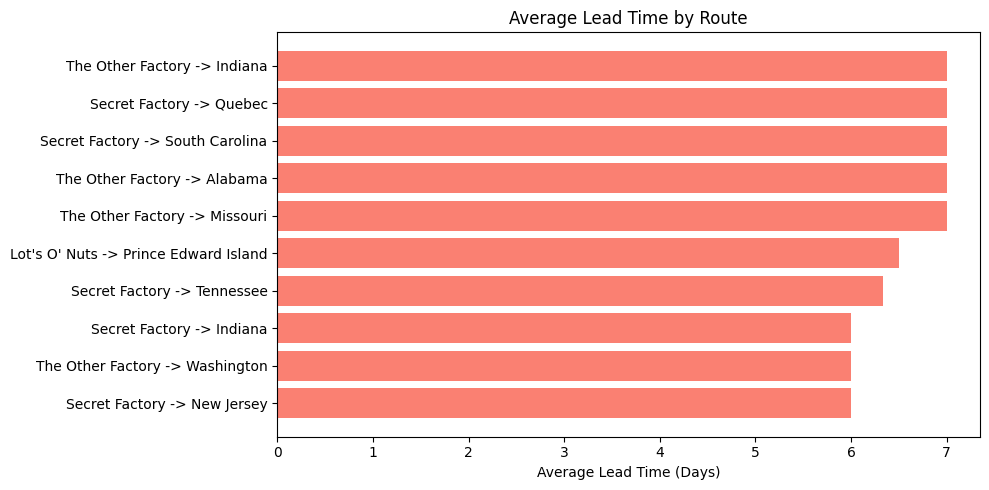

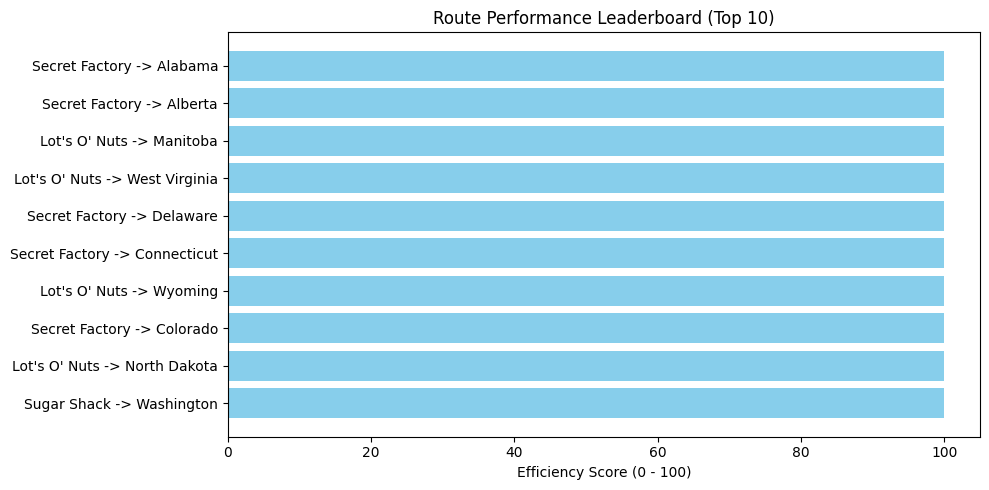

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load your cleaned dataset
df = pd.read_csv('Nassau_Candy_Cleaned_Step1.csv')

# 2. Make sure date columns are properly formatted and Lead Time exists
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# If Shipping Lead Time isn't in CSV, then
if 'Shipping Lead Time' not in df.columns:
    df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# Create the route name column if it doesn't exist
if 'Factory_to_State_Route' not in df.columns:
    df['Factory_to_State_Route'] = df['Factory'] + ' -> ' + df['State/Province']

# 3. Create a Delay Flag (True if shipping took more than 5 days)
df['Delay Flag'] = (df['Shipping Lead Time'] > 5).astype(int)

# 4. Group data by Route to get Route Volume and Average Lead Time
route_summary = df.groupby('Factory_to_State_Route').agg(
    Route_Volume=('Order ID', 'count'),
    Average_Lead_Time=('Shipping Lead Time', 'mean'),
    Delayed_Count=('Delay Flag', 'sum')
).reset_index()

# Calculate Delay Frequency (%) and Efficiency Score
route_summary['Delay_Frequency_Pct'] = (route_summary['Delayed_Count'] / route_summary['Route_Volume']) * 100
route_summary['Route_Efficiency_Score'] = 100 - route_summary['Delay_Frequency_Pct']

# 5. Create a Route Performance Leaderboard (Sorted by Efficiency Score)
route_leaderboard = route_summary.sort_values(by='Route_Efficiency_Score', ascending=False).reset_index(drop=True)
route_leaderboard.insert(0, 'Rank', route_leaderboard.index + 1)

print("--- Top 5 Routes on the Leaderboard ---")
print(route_leaderboard[['Rank', 'Factory_to_State_Route', 'Route_Volume', 'Average_Lead_Time', 'Route_Efficiency_Score']].head())



# Chart 1: Average Lead Time by Route (Top 10 highest duration routes)
plt.figure(figsize=(10, 5))
top_slow_routes = route_summary.sort_values(by='Average_Lead_Time', ascending=False).head(10)

plt.barh(top_slow_routes['Factory_to_State_Route'], top_slow_routes['Average_Lead_Time'], color='salmon')
plt.xlabel('Average Lead Time (Days)')
plt.title('Average Lead Time by Route')
plt.gca().invert_yaxis() # Puts the highest value on top
plt.tight_layout()
plt.show()

# Chart 2: Route Performance Leaderboard (Top 10 highest efficiency scores)
plt.figure(figsize=(10, 5))
top_efficient_routes = route_leaderboard.head(10)

plt.barh(top_efficient_routes['Factory_to_State_Route'], top_efficient_routes['Route_Efficiency_Score'], color='skyblue')
plt.xlabel('Efficiency Score (0 - 100)')
plt.title('Route Performance Leaderboard (Top 10)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

==================== Loading Dataset for Geographic Modules ====================
Data aggregation complete. Generating Geographic Visualizations...

==================== Geographic Visualizations ====================


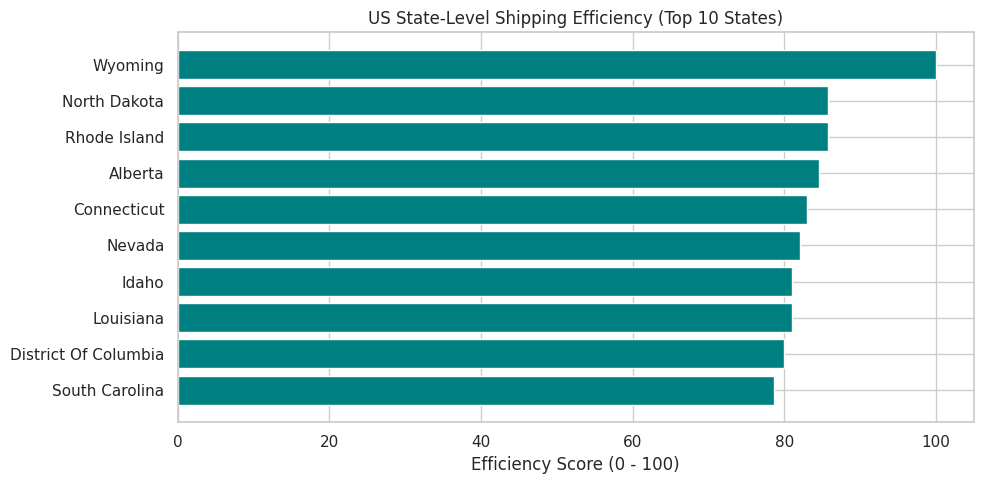

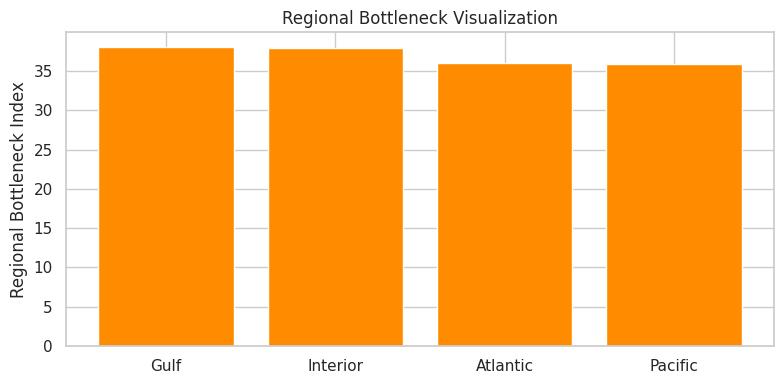

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visuals
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

print(20 * "=", "Loading Dataset for Geographic Modules", 20 * "=")

# 1. Load the cleaned dataset
df = pd.read_csv('Nassau_Candy_Cleaned_Step1.csv')

# 2. Make sure date columns are properly formatted and Lead Time exists
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

if 'Shipping Lead Time' not in df.columns:
    df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# Create a Delay Flag (True if shipping took more than 5 days)
df['Delay Flag'] = (df['Shipping Lead Time'] > 5).astype(int)

# 3. Aggregate State-Level KPIs (For US Efficiency Heatmap / Bar Chart)
state_performance = df.groupby(['State/Province', 'Region']).agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Delayed_Shipments=('Delay Flag', 'sum')
).reset_index()

state_performance['Delay_Frequency_Pct'] = (state_performance['Delayed_Shipments'] / state_performance['Total_Shipments']) * 100
state_performance['Efficiency_Score'] = 100 - state_performance['Delay_Frequency_Pct']

# 4. Aggregate Regional Bottlenecks (For Regional Bottleneck Module)
regional_performance = df.groupby('Region').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Delayed_Shipments=('Delay Flag', 'sum')
).reset_index()

regional_performance['Delay_Frequency_Pct'] = (regional_performance['Delayed_Shipments'] / regional_performance['Total_Shipments']) * 100
# Bottleneck Index: Combining delay frequency and average lead time
regional_performance['Regional_Bottleneck_Index'] = (
    (regional_performance['Delay_Frequency_Pct'] * 0.5) +
    (regional_performance['Avg_Lead_Time'] * 5)
)

print("Data aggregation complete. Generating Geographic Visualizations...\n")

print(20 * "=" ,  "Geographic Visualizations", "=" * 20)

# Chart 1: US State-Level Efficiency (Top 10 States)
plt.figure(figsize=(10, 5))
top_states = state_performance.sort_values(by='Efficiency_Score', ascending=False).head(10)

plt.barh(top_states['State/Province'], top_states['Efficiency_Score'], color='teal')
plt.xlabel('Efficiency Score (0 - 100)')
plt.title('US State-Level Shipping Efficiency (Top 10 States)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Chart 2: Regional Bottleneck Visualization
plt.figure(figsize=(8, 4))
top_bottlenecks = regional_performance.sort_values(by='Regional_Bottleneck_Index', ascending=False)

plt.bar(top_bottlenecks['Region'], top_bottlenecks['Regional_Bottleneck_Index'], color='darkorange')
plt.ylabel('Regional Bottleneck Index')
plt.title('Regional Bottleneck Visualization')
plt.tight_layout()
plt.show()

==================== Loading Dataset for Ship Mode Comparison Module ====================
Ship Mode data summary complete. Generating Visualization...

==================== Ship Mode Comparison Chart ====================


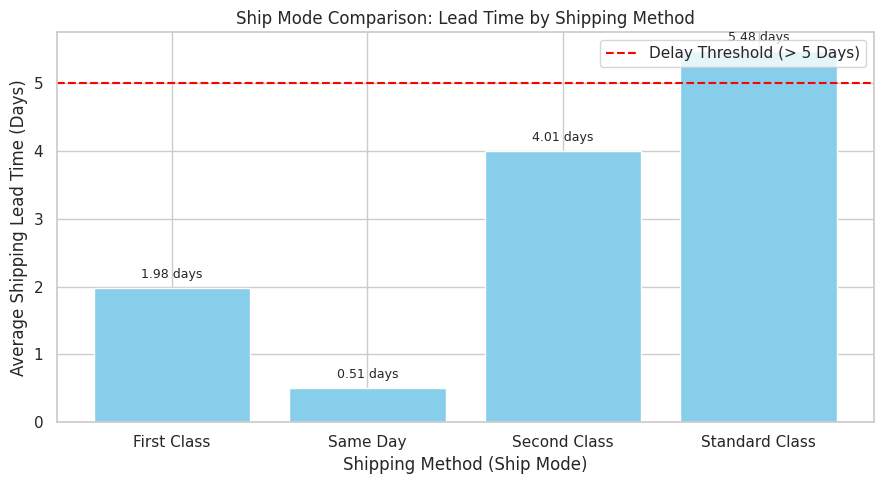

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visuals
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

print(20 * "=", "Loading Dataset for Ship Mode Comparison Module", 20 * "=")

# 1. Load the cleaned dataset
df = pd.read_csv('Nassau_Candy_Cleaned_Step1.csv')

# 2. Make sure date columns are properly formatted and Lead Time exists
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

if 'Shipping Lead Time' not in df.columns:
    df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# 3. Aggregate data by Ship Mode to get average lead times
ship_mode_summary = df.groupby('Ship Mode').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean')
).reset_index()

print("Ship Mode data summary complete. Generating Visualization...\n")

print(20 * "=" ,  "Ship Mode Comparison Chart", "=" * 20)
plt.figure(figsize=(9, 5))

# Create a bar chart comparing lead times by shipping method
bars = plt.bar(ship_mode_summary['Ship Mode'], ship_mode_summary['Avg_Lead_Time'], color='skyblue')

plt.ylabel('Average Shipping Lead Time (Days)')
plt.xlabel('Shipping Method (Ship Mode)')
plt.title('Ship Mode Comparison: Lead Time by Shipping Method')

# Add numerical labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f} days", ha='center', va='bottom', fontsize=9)

# Draw a red dashed line at the 5-day delay threshold boundary
plt.axhline(5, color='red', linestyle='--', linewidth=1.5, label='Delay Threshold (> 5 Days)')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

==================== Loading Dataset for Route Drill-Down Module ====================
State insights data complete. Generating Visualizations...

==================== Route Drill-Down Charts ====================


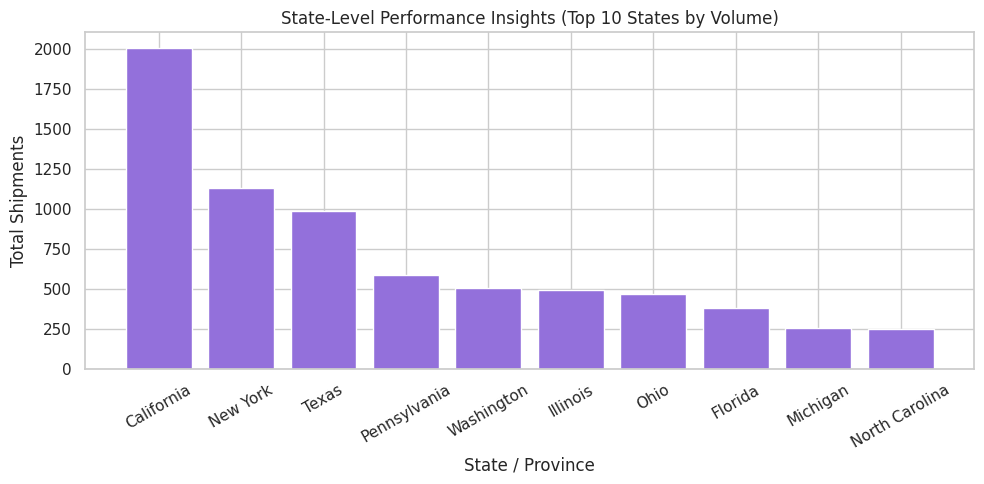

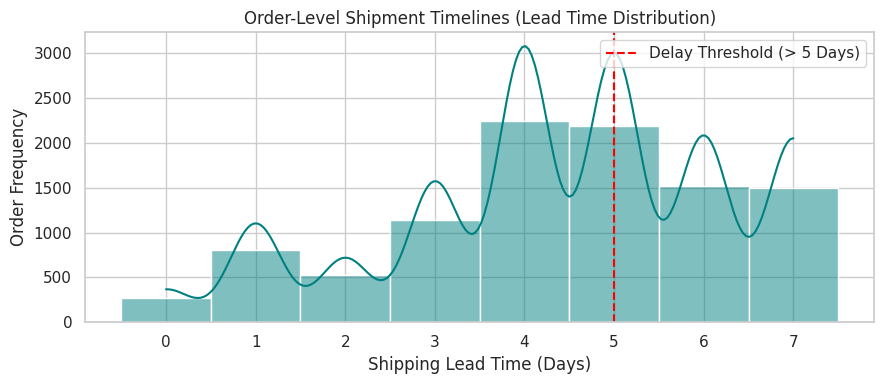

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visuals
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

print(20 * "=", "Loading Dataset for Route Drill-Down Module", 20 * "=")

# 1. Load the cleaned dataset
# Make sure 'Nassau_Candy_Cleaned_Step1.csv' is in your workspace/folder
df = pd.read_csv('Nassau_Candy_Cleaned_Step1.csv')

# 2. Make sure date columns are properly formatted and Lead Time exists
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

if 'Shipping Lead Time' not in df.columns:
    df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

# Create a Delay Flag (True if shipping took more than 5 days)
df['Delay Flag'] = (df['Shipping Lead Time'] > 5).astype(int)

# 3. Aggregate State-Level Performance Insights
state_insights = df.groupby('State/Province').agg(
    Total_Shipments=('Order ID', 'count'),
    Avg_Lead_Time=('Shipping Lead Time', 'mean'),
    Delayed_Shipments=('Delay Flag', 'sum')
).reset_index()

state_insights['Delay_Frequency_Pct'] = (state_insights['Delayed_Shipments'] / state_insights['Total_Shipments']) * 100
state_insights['Efficiency_Score'] = 100 - state_insights['Delay_Frequency_Pct']

print("State insights data complete. Generating Visualizations...\n")

print(20 * "=", "Route Drill-Down Charts", "=" * 20)

# Chart 1: State-Level Performance Insights (Top 10 States by Shipment Volume)
plt.figure(figsize=(10, 5))
top_states = state_insights.sort_values(by='Total_Shipments', ascending=False).head(10)

plt.bar(top_states['State/Province'], top_states['Total_Shipments'], color='mediumpurple')
plt.ylabel('Total Shipments')
plt.xlabel('State / Province')
plt.title('State-Level Performance Insights (Top 10 States by Volume)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Chart 2: Order-Level Shipment Timelines (Distribution of Lead Times in Days)
plt.figure(figsize=(9, 4))
sns.histplot(df['Shipping Lead Time'], bins=7, discrete=True, color='teal', kde=True)

plt.xlabel('Shipping Lead Time (Days)')
plt.ylabel('Order Frequency')
plt.title('Order-Level Shipment Timelines (Lead Time Distribution)')
plt.axvline(5, color='red', linestyle='--', linewidth=1.5, label='Delay Threshold (> 5 Days)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
print("Actual Columns in CSV:", df.columns.tolist())

Actual Columns in CSV: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time', 'Factory', 'Factory Latitude', 'Factory Longitude', 'Factory_to_Region_Route', 'Factory_to_State_Route', 'Delay Flag', 'Shipping_Tier']


==================== Loading and Inspecting Dataset ====================
-> Available Regions in your data: ['Interior', 'Atlantic', 'Gulf', 'Pacific']
-> Available Ship Modes in your data: ['Standard Class', 'First Class', 'Second Class', 'Same Day']

==================== User Capabilities / Filter Control Panel ====================
Active Filters -> Region: [Interior] | Ship Mode: [Standard Class] | Threshold: [5 Days]

--- Dataset Summary ---
Total Global Orders: 10,194
Overall Average Lead Time: 4.40 days
Filtered Orders Matching Criteria: 858
Filtered Average Lead Time: 5.49 days
Delayed Orders (> 5 days): 431

==================== Generating Filtered Visualizations ====================


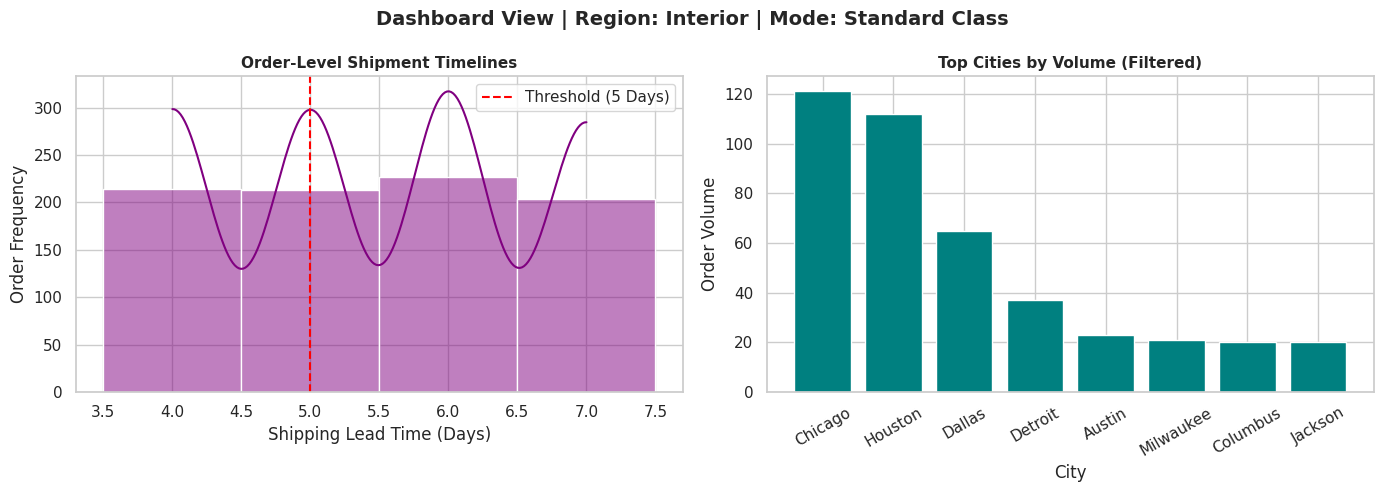

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visuals
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

print(20 * "=", "Loading and Inspecting Dataset", 20 * "=")

# 1. Load the dataset
df = pd.read_csv('Nassau_Candy_Cleaned_Step1.csv')

# Clean text columns
df['City'] = df['City'].fillna("Unknown").astype(str).str.strip()
df['Region'] = df['Region'].astype(str).str.strip()
df['Ship Mode'] = df['Ship Mode'].astype(str).str.strip()

# Print available options to console
print(f"-> Available Regions in your data: {df['Region'].unique().tolist()}")
print(f"-> Available Ship Modes in your data: {df['Ship Mode'].unique().tolist()}\n")

# 2. Format date columns and calculate Lead Time if missing
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

if 'Shipping Lead Time' not in df.columns:
    df['Shipping Lead Time'] = (df['Ship Date'] - df['Order Date']).dt.days

print(20 * "=", "User Capabilities / Filter Control Panel", "=" * 20)


# USER FILTERS

selected_region = 'Interior'
selected_ship_mode = 'Standard Class'
lead_time_threshold = 5

# Date Range Filter Setup
start_date = '2025-01-01'
end_date = '2025-12-31'

print(f"Active Filters -> Region: [{selected_region}] | Ship Mode: [{selected_ship_mode}] | Threshold: [{lead_time_threshold} Days]\n")

# 3. APPLY FILTERS TO THE DATASET
mask = (
    (df['Order Date'] >= start_date) &
    (df['Order Date'] <= end_date) &
    (df['Region'] == selected_region) &
    (df['Ship Mode'] == selected_ship_mode)
)

filtered_df = df[mask].copy()

# Apply dynamic delay flag based on the lead-time threshold
filtered_df['Delay Flag'] = (filtered_df['Shipping Lead Time'] > lead_time_threshold).astype(int)

# Print Summary Metrics
print(f"--- Dataset Summary ---")
print(f"Total Global Orders: {len(df):,}")
print(f"Overall Average Lead Time: {df['Shipping Lead Time'].mean():.2f} days")
print(f"Filtered Orders Matching Criteria: {len(filtered_df):,}")

if not filtered_df.empty:
    print(f"Filtered Average Lead Time: {filtered_df['Shipping Lead Time'].mean():.2f} days")
    print(f"Delayed Orders (> {lead_time_threshold} days): {filtered_df['Delay Flag'].sum()}\n")

# 4. VISUALIZATIONS FOR FILTERED DATA
print(20 * "=", "Generating Filtered Visualizations", "=" * 20)

if not filtered_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Dashboard View | Region: {selected_region} | Mode: {selected_ship_mode}", fontsize=14, fontweight='bold')

    # Chart A: Lead Time Distribution Histogram
    sns.histplot(
        filtered_df['Shipping Lead Time'],
        bins=7,
        discrete=True,
        color='purple',
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title("Order-Level Shipment Timelines", fontsize=11, fontweight='bold')
    axes[0].set_xlabel("Shipping Lead Time (Days)")
    axes[0].set_ylabel("Order Frequency")
    axes[0].axvline(lead_time_threshold, color='red', linestyle='--', linewidth=1.5, label=f'Threshold ({lead_time_threshold} Days)')
    axes[0].legend(loc='upper right')

    # Chart B: City-Level Volume Breakdown (Replaces missing State data)
    valid_cities = filtered_df[
        (filtered_df['City'] != 'nan') &
        (filtered_df['City'] != 'Unknown') &
        (filtered_df['City'] != '')
    ]

    city_counts = valid_cities['City'].value_counts().head(8)

    if not city_counts.empty:
        axes[1].bar(city_counts.index, city_counts.values, color='teal')
        axes[1].set_title("Top Cities by Volume (Filtered)", fontsize=11, fontweight='bold')
        axes[1].set_xlabel("City")
        axes[1].set_ylabel("Order Volume")
        axes[1].tick_params(axis='x', rotation=30)
    else:
        axes[1].text(0.5, 0.5, "No City Data Available", horizontalalignment='center', verticalalignment='center', transform=axes[1].transAxes)

    plt.tight_layout()
    plt.show()
else:
    print("No records match your selected filter criteria.")